# Transformer + frozen GloVe (Final Run)

The configuration was chosen on dev only, in `colab_run.ipynb`, whose results are logged in `results/ablations.jsonl`.
This notebook:

1. shows that selection again, from the log
2. trains the chosen configuration (the **default**) once and saves the best-dev-epoch checkpoint
3. reloads the checkpoint from disk and checks that its dev score equals the logged best
4. only then scores **test, once**

In [1]:
import json, os, platform, sys, time
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch

from sc4002.experiments import EXPERIMENTS
from sc4002.metrics import fmt
from sc4002.model import count_params
from sc4002.train import PARAM_CAP, RESULTS, Config, build, evaluate, fit, load_checkpoint, pick_device

print('python', sys.version.split()[0], '| torch', torch.__version__, '|', platform.machine(),
      '| threads', torch.get_num_threads())
print('results ->', RESULTS)

python 3.12.12 | torch 2.14.1 | arm64 | threads 5
results -> /Users/wei/SC4002/results


## 1. Selection (dev only), from `results/ablations.jsonl`

In [2]:
rows = [json.loads(l) for l in open(RESULTS / 'ablations.jsonl') if l.strip()]
runs = pd.DataFrame([{'exp': r['exp'], 'seed': r['config']['seed'], 'best_epoch': r['best_epoch'],
                      'intent': r['dev_intent_acc'], 'slot': r['dev_slot_f1'], 'combined': r['dev_combined'],
                      'total_params': r['total_params']} for r in rows])
r1 = runs.query('seed == 42').set_index('exp').sort_values('combined', ascending=False)
r1['delta_vs_default'] = r1['combined'] - r1.loc['default', 'combined']
print('Round 1 (seed 42):')
r1.round(2)

Round 1 (seed 42):


,seed,best_epoch,intent,slot,combined,total_params,delta_vs_default
exp,,,,,,,
no_char,42,31,87.85,82.34,85.10,19999747,0.31
tok_clitic,42,32,87.70,82.33,85.01,19999735,0.23
default,42,37,87.65,81.91,84.78,19999735,0.00
no_intent_cond,42,29,87.31,81.40,84.36,19999819,-0.43
tok_bpe2k,42,33,87.16,81.31,84.24,19999831,-0.54
dec_softmax,42,32,88.19,78.65,83.42,19999792,-1.36
topk_0,42,30,86.52,80.17,83.35,10033135,-1.44
no_glove,42,39,86.08,80.46,83.27,8427535,-1.51


In [3]:
CANDIDATES = ['default'] + r1.drop(index='default').index[:3].tolist()
r2 = runs[runs.exp.isin(CANDIDATES) & runs.seed.isin([42, 43, 44])]
assert len(r2) == 12, len(r2)
summary = r2.groupby('exp').agg(intent=('intent', 'mean'), slot=('slot', 'mean'), combined=('combined', 'mean'),
                                combined_std=('combined', 'std')).sort_values('combined', ascending=False)
summary['delta_vs_default'] = summary['combined'] - summary.loc['default', 'combined']
CHOSEN = summary.index[0]
print('Round 2 (seeds 42, 43, 44), chosen:', CHOSEN, EXPERIMENTS[CHOSEN])
summary.round(2)

Round 2 (seeds 42, 43, 44), chosen: default {}


,intent,slot,combined,combined_std,delta_vs_default
exp,,,,,
default,87.64,82.03,84.83,0.17,0.00
no_char,87.28,82.20,84.74,0.31,-0.10
no_intent_cond,87.75,81.69,84.72,0.32,-0.11
tok_clitic,87.51,81.62,84.56,0.50,-0.27


## 2. Train the chosen configuration and save the checkpoint
40 epochs; dev is scored after every epoch and the best dev-combined epoch is kept (`*`).

In [4]:
cfg = Config(**{**EXPERIMENTS[CHOSEN], 'seed': 42})
built = build(cfg)
total, trainable = count_params(built[2])
assert total <= PARAM_CAP, total
print(f'total parameters {total:,} (cap {PARAM_CAP:,}), trainable {trainable:,}, device {pick_device(cfg)}')

units 5304  chars 34  frozen table 38190x300  params total 19,999,735  trainable 8,542,735
total parameters 19,999,735 (cap 20,000,000), trainable 8,542,735, device cpu


In [5]:
NAME = f'wl_final_{CHOSEN}_s{cfg.seed}'
run = fit(cfg, name=NAME, save_checkpoint=True, built=built)
CKPT = Path(run['checkpoint'])
log = {k: v for k, v in run.items() if k not in ('model', 'encoder', 'data')}
(RESULTS / 'final_run.json').write_text(json.dumps(log, indent=1))
print()
print(f"best epoch {run['best_epoch']}  dev intent acc {run['dev_intent_acc']:.2f}  slot F1 {run['dev_slot_f1']:.2f}  "
      f"combined {run['dev_combined']:.2f}")
print(f"checkpoint {CKPT}  ({CKPT.stat().st_size / 1e6:.1f} MB)   training time {run['train_time'] / 60:.1f} min")

epoch  1  train loss 3.8356  dev loss 1.4523  dev intent acc 70.54  slot F1 57.28  combined 63.91  39.2s  *


epoch  2  train loss 1.9090  dev loss 0.9906  dev intent acc 81.70  slot F1 69.07  combined 75.38  38.0s  *


epoch  3  train loss 1.6233  dev loss 0.9155  dev intent acc 83.03  slot F1 69.77  combined 76.40  37.8s  *


epoch  4  train loss 1.4960  dev loss 0.8708  dev intent acc 83.28  slot F1 73.89  combined 78.58  37.2s  *


epoch  5  train loss 1.3985  dev loss 0.8273  dev intent acc 84.11  slot F1 75.07  combined 79.59  37.4s  *


epoch  6  train loss 1.3377  dev loss 0.8029  dev intent acc 85.24  slot F1 74.87  combined 80.06  37.9s  *


... (31 outputs left out)

epoch 38  train loss 0.7857  dev loss 0.8553  dev intent acc 87.60  slot F1 83.11  combined 85.36  38.0s  *


epoch 39  train loss 0.7841  dev loss 0.8557  dev intent acc 87.70  slot F1 83.08  combined 85.39  38.1s  *


epoch 40  train loss 0.7832  dev loss 0.8556  dev intent acc 87.70  slot F1 83.08  combined 85.39  38.9s



best epoch 39  dev intent acc 87.70  slot F1 83.08  combined 85.39
checkpoint /Users/wei/SC4002/checkpoints/wl_final_default_s42.pt  (80.0 MB)   training time 25.5 min


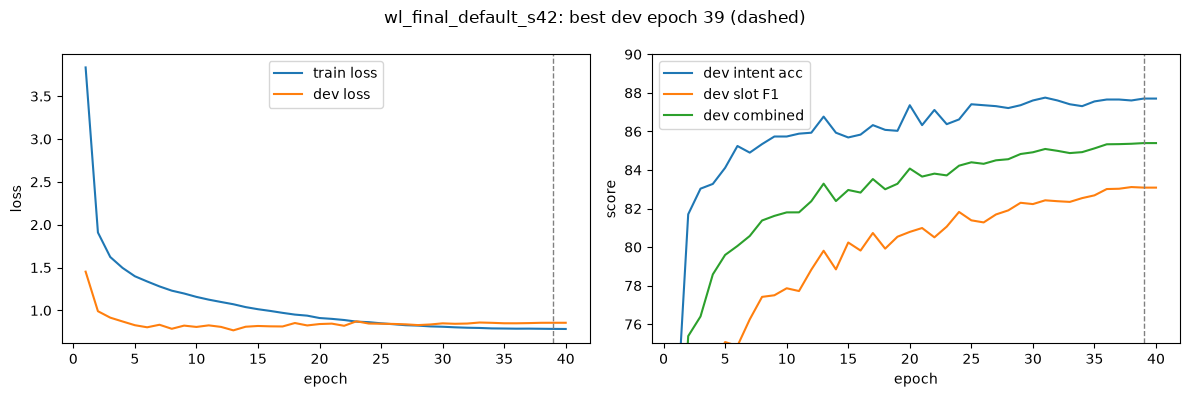

In [6]:
h = pd.DataFrame(run['history'])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h.epoch, h.train_loss, label='train loss')
ax[0].plot(h.epoch, h.dev_loss, label='dev loss')
ax[0].set_xlabel('epoch'); ax[0].set_ylabel('loss'); ax[0].legend()
for col, lab in [('dev_intent_acc', 'dev intent acc'), ('dev_slot_f1', 'dev slot F1'), ('dev_combined', 'dev combined')]:
    ax[1].plot(h.epoch, h[col], label=lab)
for a in ax:
    a.axvline(run['best_epoch'], color='grey', ls='--', lw=1)
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('score'); ax[1].set_ylim(75, 90); ax[1].legend()
fig.suptitle(f"{NAME}: best dev epoch {run['best_epoch']} (dashed)")
fig.tight_layout()
fig.savefig(RESULTS / 'final_curves.png', dpi=120)
plt.show()

## 3. Reload the checkpoint and check dev
The model is rebuilt from the config stored in the checkpoint and the saved weights are loaded; its dev score must equal the logged best exactly.

In [7]:
del run, built
model, enc, data, ck = load_checkpoint(CKPT)
device = pick_device(Config(**ck['config']))
model.to(device)
print('checkpoint:', CKPT.name, '| epoch', ck['epoch'], '| params', f"{ck['params'][0]:,}")
dev, _ = evaluate(model, enc, data['dev'], device)
print('reloaded dev:', fmt(dev))
print('logged best :', f"intent acc {ck['dev']['dev_intent_acc']:.2f}  slot F1 {ck['dev']['dev_slot_f1']:.2f}  "
      f"combined {ck['dev']['dev_combined']:.2f}")
assert dev['intent_acc'] == ck['dev']['dev_intent_acc'] and dev['slot_f1'] == ck['dev']['dev_slot_f1']
print('OK: reloaded dev score equals the logged best')

checkpoint: wl_final_default_s42.pt | epoch 39 | params 19,999,735


reloaded dev: intent acc 87.70  slot F1 83.08  combined 85.39
logged best : intent acc 87.70  slot F1 83.08  combined 85.39
OK: reloaded dev score equals the logged best


## 4. Test, scored once
Nothing below feeds back into any choice.

In [8]:
test, test_preds = evaluate(model, enc, data['test'], device)
print(f'TEST ({len(data["test"])} utterances): {fmt(test)}')
scores = dict(checkpoint=CKPT.name, best_epoch=ck['epoch'], config=ck['config'],
              total_params=ck['params'][0], trainable_params=ck['params'][1],
              dev={k: dev[k] for k in ('intent_acc', 'slot_f1', 'combined')},
              test={k: test[k] for k in ('intent_acc', 'slot_f1', 'combined', 'tp', 'fp', 'fn')})
(RESULTS / 'final_scores.json').write_text(json.dumps(scores, indent=1))
with open(RESULTS / 'final_test_predictions.jsonl', 'w') as f:
    for p in test_preds:
        f.write(json.dumps(p) + '\n')
pd.DataFrame({'dev': scores['dev'], 'test': {k: test[k] for k in ('intent_acc', 'slot_f1', 'combined')}}).round(2)

TEST (2974 utterances): intent acc 87.09  slot F1 81.01  combined 84.05


,dev,test
intent_acc,87.70,87.09
slot_f1,83.08,81.01
combined,85.39,84.05
